# Movie Match: semantic movie recommendation

**ECE ING5 Data & AI, Natural Language Processing project (2026-2027), Theme 1: movie recommendation based on semantic analysis.**

This notebook is the documented walkthrough of our source code. It does not re-implement the engine: it imports the same `backend` modules that the web application uses, and runs every step of the pipeline on the real 150-film corpus so that each intermediate result can be inspected.

| Step | Assignment requirement | Section |
| --- | --- | --- |
| Reference dataset (origin, structure, preprocessing) | Requirement 2 | 2 |
| Text preprocessing and contextual embeddings (SBERT) | Requirement 3 | 3, 4 |
| Questionnaire answers as a structured profile | Requirement 1 | 5 |
| Scoring formula, weights, thresholds and constraints | Requirement 4 | 6 |
| Top 3 recommendations with score, criteria and explanation | Requirement 5 | 7 |
| Visualisations: bars, radar, similarity map | Requirement 6 | 8 |
| Semantic vs keyword comparison and measured quality | Learning goals | 9, 10 |

**How to run it.** Follow the README setup first (virtual environment and `python -m scripts.prepare_model`), then install the notebook extras with `pip install -r requirements-notebook.txt` and open this file with the project's `.venv` kernel. Everything runs offline on CPU in under a minute.

## 1. Setup

In [1]:
# Standard libraries and the numerical / plotting stack.
import json
import logging
import os
import sys
import warnings

# Keep the outputs readable: hide download progress bars and library notices.
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["TQDM_DISABLE"] = "1"
warnings.filterwarnings("ignore")
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The notebook lives in notebooks/, the backend package in the project root.
ROOT = Path.cwd().resolve()
if not (ROOT / "backend").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

# Project modules: exactly the code served by the FastAPI application.
from backend.catalog import eligible, load_catalog, movie_texts
from backend.config import CACHE_PATH, CORPUS_PATH, LABELS, MODEL_PATH, WEIGHTS
from backend.embeddings import SentenceEncoder, clean_text
from backend.recommender import Recommender, summarise
from backend.schemas import Importance, Preferences

pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Project root:", ROOT)

Project root: /Users/ethan/Development/ecole/Projet_NLP


## 2. Reference dataset

**Origin.** 150 real films selected from the public *TMDB 5000* metadata snapshot (Kaggle, releases up to 2016). The selection balances genre and decade buckets. Titles, synopses, genres, years, runtimes and keyword tags come from the source; the archive checksum and a corpus fingerprint are stored in `data/movies.manifest.json`.

**Structure.** One record per film, following the structure suggested by the assignment (`MovieID | Category | Genre | Synopsis | Themes | Mood | Keywords`):

| Field | Origin | Role in matching |
| --- | --- | --- |
| `overview` | source synopsis | story criterion |
| `themes` | source keyword tags | themes criterion and topic filter |
| `mood` | estimated label (see below) | atmosphere criterion |
| `narrative_style` | estimated label | storytelling criterion |
| `setting` | cues extracted from the source text | setting criterion |
| `genres` | source genres | genre criterion and genre filter |
| `release_year`, `runtime_minutes` | source | strict filters |

**Preprocessing.** Records are validated by Pydantic (types, duplicates, empty lists). Atmosphere and storytelling labels are chosen among 10 fixed English descriptions by cosine similarity with the film text; below 0.15 the label stays unknown (`null`) instead of being invented.

In [2]:
# Load and validate the corpus with the same Pydantic schema as the API.
movies = load_catalog(CORPUS_PATH)
print(f"{len(movies)} films loaded and validated")

# Flatten the records into a table for inspection.
corpus = pd.DataFrame([m.model_dump() for m in movies])
corpus[["tmdb_id", "title", "release_year", "genres", "themes", "mood", "narrative_style", "setting"]].head(5)

150 films loaded and validated


,tmdb_id,title,release_year,genres,themes,mood,narrative_style,setting
0,27205,Inception,2010,"[Action, Thriller, Science Fiction, Mystery, Adventure]","[loss of lover, dream, kidnapping, sleep, subconsciousness, heist, redemption, female ...","An adventurous, exciting atmosphere with a sense of discovery.","An investigation narrative built around a mystery, clues and revelations.",NaN
1,157336,Interstellar,2014,"[Adventure, Drama, Science Fiction]","[saving the world, artificial intelligence, father son relationship, single parent, na...","An adventurous, exciting atmosphere with a sense of discovery.","An adventure narrative built around a journey, obstacles and discovery.",Setting cues in the source keywords: space travel; dystopia; spaceship.
2,550,Fight Club,1999,[Drama],"[support group, dual identity, nihilism, rage and hate, insomnia, dystopia, violence]","A moving, emotional and bittersweet atmosphere.",A survival narrative about people facing isolation and a hostile environment.,Setting cues in the source keywords: dystopia.
3,120,The Lord of the Rings: The Fellowship of the Ring,2001,"[Adventure, Fantasy, Action]","[elves, dwarves, orcs, middle-earth (tolkien), hobbit, mountains, fireworks, castle, v...","A magical, imaginative and dreamlike atmosphere.","An adventure narrative built around a journey, obstacles and discovery.",NaN
4,13,Forrest Gump,1994,"[Comedy, Drama, Romance]","[vietnam veteran, hippie, mentally disabled, running, vietnam, vietnam war, friendship...","A tragic, sorrowful atmosphere shaped by loss and grief.","A romantic narrative focused on attraction, relationships and emotional choices.",Setting cues in the source keywords: vietnam veteran; vietnam; vietnam war.


In [3]:
# How complete is each text attribute? Missing values are kept explicit (None), never filled in.
completeness = pd.DataFrame({
    "available": corpus[["overview", "themes", "mood", "narrative_style", "setting"]].notna().sum(),
})
completeness["missing"] = len(corpus) - completeness["available"]
completeness

,available,missing
overview,150,0
themes,150,0
mood,136,14
narrative_style,146,4
setting,100,50


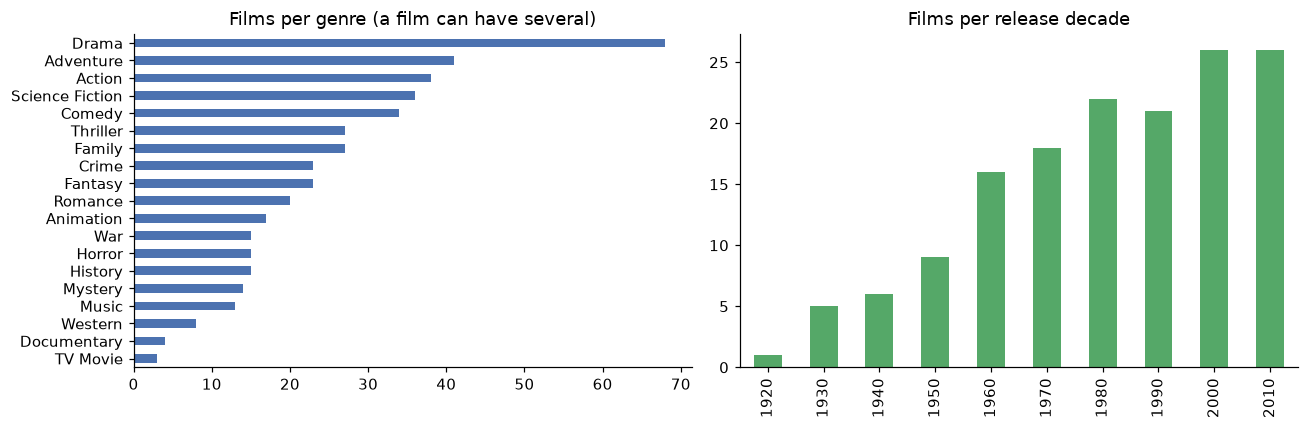

In [4]:
# Distribution of genres and decades: the selection was balanced on both axes.
genre_counts = Counter(g for genres in corpus["genres"] for g in genres)
decades = (corpus["release_year"] // 10 * 10).value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pd.Series(genre_counts).sort_values().plot.barh(ax=axes[0], color="#4c72b0")
axes[0].set_title("Films per genre (a film can have several)")
decades.plot.bar(ax=axes[1], color="#55a868")
axes[1].set_title("Films per release decade")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

## 3. Text preprocessing

Preprocessing is deliberately light. Sentence encoders are trained on natural sentences, so removing stop words, lemmatising or lower-casing would destroy information the model uses: negations (*not*, *without*), word order and punctuation all change meaning. We only:

1. normalise whitespace (`clean_text`);
2. build one text per criterion for every film (`movie_texts`);
3. split texts longer than the model window (256 word pieces) into token chunks, encode each chunk and average the normalised vectors.

In [5]:
# 1. Whitespace normalisation keeps punctuation and negations.
print(repr(clean_text("  A heist   film,\n but NOT a comedy!  ")))

# 2. The six criterion texts of one film, as the scorer sees them.
inception = next(m for m in movies if m.title == "Inception")
pd.Series(movie_texts(inception), name="Inception").to_frame()

'A heist film, but NOT a comedy!'


,Inception
description,"Cobb, a skilled thief who commits corporate espionage by infiltrating the subconscious..."
themes,loss of lover; dream; kidnapping; sleep; subconsciousness; heist; redemption; female hero
mood,"An adventurous, exciting atmosphere with a sense of discovery."
narrative_style,"An investigation narrative built around a mystery, clues and revelations."
setting,
genres,"Action, Thriller, Science Fiction, Mystery, Adventure"


## 4. Contextual embeddings with SBERT

**Model choice.** `sentence-transformers/all-MiniLM-L6-v2` (Sentence-BERT family). It maps a sentence or short paragraph to a 384-dimensional vector and was trained with a contrastive objective on over one billion sentence pairs, so that paraphrases land close together. We chose it because:

* user requests and film descriptions are *sentences*, not isolated words: static word embeddings (Word2Vec, GloVe, fastText) average word vectors and lose context and word order;
* it is small (22 M parameters, about 90 MB) and fast on a laptop CPU, so the demo runs offline in tens of milliseconds;
* its vectors are L2-normalised, so cosine similarity is a simple dot product.

**Similarity measure.** Cosine similarity compares directions, not lengths, so a long synopsis is not favoured over a short label. Negative cosines (opposite meaning) are clipped to 0 in the score.

In [6]:
# Load the local copy of the encoder (downloaded once by scripts.prepare_model).
encoder = SentenceEncoder(MODEL_PATH, CACHE_PATH)
vectors = encoder.encode(["A detective hunts a serial killer in a rainy city."])
print("Vector shape:", vectors.shape, "| L2 norm:", round(float(np.linalg.norm(vectors[0])), 4))

Vector shape: (1, 384) | L2 norm: 1.0


### Semantic vs keyword similarity

The core claim of the project: two sentences can mean the same thing with no word in common, and share words while meaning something different. We compare TF-IDF cosine (keyword overlap) with SBERT cosine on such pairs.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

pairs = [
    ("A film about a robot that develops feelings", "An artificial intelligence learns to love"),
    ("A scary movie set in a haunted house", "A terrifying story in a mansion full of ghosts"),
    ("A light comedy about friendship", "A tragic war drama about loss"),
    ("The bank of the river was flooded", "The bank raised its interest rates"),
]
rows = []
for a, b in pairs:
    # TF-IDF fitted on the pair only: it only sees shared surface words.
    tfidf = TfidfVectorizer().fit([a, b])
    lexical = cosine_similarity(tfidf.transform([a]), tfidf.transform([b]))[0, 0]
    # SBERT: normalised vectors, so the dot product is the cosine similarity.
    va, vb = encoder.encode([a, b])
    rows.append({"sentence A": a, "sentence B": b, "TF-IDF cosine": round(lexical, 2), "SBERT cosine": round(float(va @ vb), 2)})
pd.DataFrame(rows)

,sentence A,sentence B,TF-IDF cosine,SBERT cosine
0,A film about a robot that develops feelings,An artificial intelligence learns to love,0.00,0.57
1,A scary movie set in a haunted house,A terrifying story in a mansion full of ghosts,0.08,0.70
2,A light comedy about friendship,A tragic war drama about loss,0.13,0.41
3,The bank of the river was flooded,The bank raised its interest rates,0.27,0.44


The first two pairs share almost no words (TF-IDF close to 0) but SBERT recognises the paraphrase. The last pair shares the word *bank* in two different senses: the contextual model keeps the similarity moderate. This is why lexical matching is only used as a baseline in our application.

### How the atmosphere labels were estimated

The same mechanism annotated the corpus: each film text is compared with fixed atmosphere descriptions and the closest one is kept if its similarity reaches 0.15. Below, the similarity of a few films with each atmosphere label.

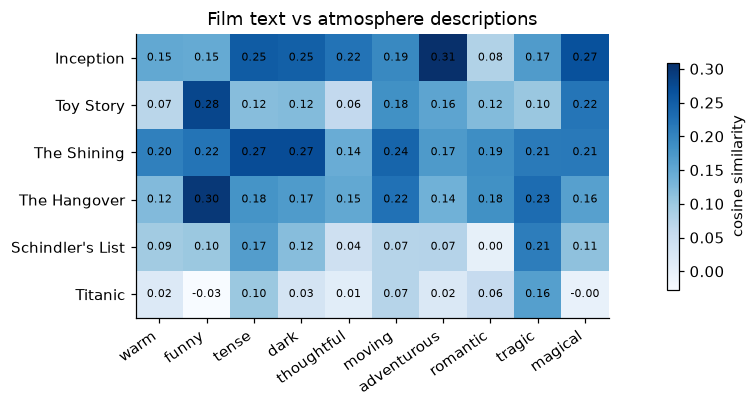

In [8]:
from scripts.prepare_catalog import MOODS

sample = [m for m in movies if m.title in {"Inception", "The Shining", "Toy Story", "Titanic", "Schindler's List", "The Hangover"}]
film_vectors = encoder.encode([f"{m.title}. {m.overview}" for m in sample])
mood_vectors = encoder.encode(MOODS)
heat = film_vectors @ mood_vectors.T

fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(heat, cmap="Blues")
ax.set_yticks(range(len(sample)), [m.title for m in sample])
ax.set_xticks(range(len(MOODS)), [label.split(",")[0].replace("A ", "").replace("An ", "") for label in MOODS], rotation=35, ha="right")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8, label="cosine similarity")
ax.set_title("Film text vs atmosphere descriptions")
plt.tight_layout()
plt.show()

## 5. From the questionnaire to a user profile

The web questionnaire combines every question type required by the assignment. Each answer is mapped to a field of the `Preferences` model:

| Question type | Questionnaire item | Field | Use |
| --- | --- | --- | --- |
| Open-ended | *Describe the film you want to watch* | `description` | semantic criterion (required) |
| Guided text | themes, atmosphere, storytelling, setting | `themes`, `mood`, `narrative_style`, `setting` | semantic criteria |
| Checkboxes | preferred genres / excluded genres | `preferred_genres`, `excluded_genres` | semantic criterion / strict filter |
| Single choice | release era, comparison method | `release_period`, `method` | strict filter / engine choice |
| Multiple selection | excluded topics, films already watched | `excluded_themes`, `seen_movie_ids` | strict filters |
| Likert 1 to 5 | importance of each criterion | `importance` | weights of the score |

Text answers carry the meaning; the numeric answers only weight or filter. Below is the example request from the assignment, completed as a user would fill the form.

In [9]:
profile = Preferences(
    # Open-ended question (example sentence from the assignment, Theme 1).
    description="I would like to watch an emotional science-fiction movie exploring human relationships, "
                "artificial intelligence, and the future of society.",
    # Guided text questions.
    themes="artificial intelligence, love and loneliness",
    mood="moving and thoughtful",
    narrative_style="an intimate character-driven story",
    # Checkboxes.
    preferred_genres=["Science Fiction", "Drama"],
    # Likert scales (1 = not important, 5 = essential).
    importance=Importance(description=5, themes=4, mood=4, narrative_style=2, setting=1, genres=2),
    # Single choice and strict limit.
    release_period="any",
    max_runtime=150,
)
# Structured record that the API stores (with consent) as one JSON line.
print(json.dumps(profile.model_dump(exclude={"save_response"}), indent=1)[:900])
print()
print("Generated preference summary:")
print(summarise(profile))

{
 "description": "I would like to watch an emotional science-fiction movie exploring human relationships, artificial intelligence, and the future of society.",
 "themes": "artificial intelligence, love and loneliness",
 "mood": "moving and thoughtful",
 "narrative_style": "an intimate character-driven story",
 "setting": "",
 "preferred_genres": [
  "Science Fiction",
  "Drama"
 ],
 "importance": {
  "description": 5,
  "themes": 4,
  "mood": 4,
  "narrative_style": 2,
  "setting": 1,
  "genres": 2
 },
 "max_runtime": 150,
 "excluded_genres": [],
 "excluded_themes": [],
 "seen_movie_ids": [],
 "release_period": "any",
 "method": "sbert_criteria"
}

Generated preference summary:
You are looking for: I would like to watch an emotional science-fiction movie exploring human relationships, artificial intelligence, and the future of society. Themes: artificial intelligence, love and loneliness. Atmosphere: moving and thoughtful. Storytelling: an intimate character-driven story. Genres: Scie

## 6. Scoring mechanism

For a film $f$ and the set $A(f)$ of criteria that are both answered by the user and available for the film:

$$\text{Affinity}(f) = 100 \times \frac{\sum_{b \in A(f)} w_b \, i_b \, \max\big(0, \cos(u_b, f_b)\big)}{\sum_{b \in A(f)} w_b \, i_b}$$

* $u_b$ and $f_b$: SBERT vectors of the user answer and of the film text for criterion $b$;
* $w_b$: base weight of the criterion (below), $i_b$: Likert importance from 1 to 5;
* this is the weighted coverage formula of the assignment, $\sum W_i S_i / \sum W_i$, with $W_i = w_b \, i_b$ and $S_i$ the cosine similarity.

**Justification of the base weights.** The synopsis carries the most information and is always present (35 %); keyword themes are precise and present for most films (25 %); atmosphere is what users mention most after the plot but is an estimated label (15 %); storytelling and setting are secondary or often missing (10 % each); genres are coarse and already covered by the strict genre filter (5 %).

**Design choices.**
* *Renormalisation*: a criterion missing for a film is removed from both sums, so the film is neither rewarded nor punished for a missing annotation (the missing field is reported to the user).
* *Clipping at 0*: an opposite meaning gives no points but does not subtract.
* *Story vs whole profile*: the free description is compared with the whole film profile (synopsis + all attributes), because users mix plot, tone and genre in that answer. This option was selected on validation queries (section 10).
* *Strict filters before scoring*: era, duration, excluded genres or topics and watched films remove candidates; negative wishes are never put into the embedding, because sentence encoders handle negation poorly.

In [10]:
# Build the recommender exactly as the API does (criterion-level SBERT, story vs whole profile).
recommender = Recommender(movies, encoder)
active = {k: v for k, v in profile.criterion_texts().items() if v}
similarities = recommender._criterion_similarities(active)

# Manual computation of the formula for one film, step by step.
film_index = next(i for i, m in enumerate(movies) if m.title == "Her") if any(m.title == "Her" for m in movies) else 0
film = movies[film_index]
importance = profile.importance.model_dump()
rows = []
for key in active:
    if not recommender.compared[film_index][key]:
        continue  # criterion missing for this film: excluded from both sums
    s = float(np.clip(similarities[key][film_index], 0, 1))  # negative cosine -> 0
    rows.append({"criterion": LABELS[key], "cosine S": s, "base w": WEIGHTS[key],
                 "importance i": importance[key], "W = w*i": WEIGHTS[key] * importance[key]})
table = pd.DataFrame(rows)
table["W*S"] = table["W = w*i"] * table["cosine S"]
manual = 100 * table["W*S"].sum() / table["W = w*i"].sum()
print(f"Film: {film.title} ({film.release_year})")
display(table.round(3))
print(f"Manual affinity = 100 * {table['W*S'].sum():.3f} / {table['W = w*i'].sum():.2f} = {manual:.2f}")

Film: Her (2013)


,criterion,cosine S,base w,importance i,W = w*i,W*S
0,Story,0.416,0.35,5,1.75,0.729
1,Themes,0.697,0.25,4,1.00,0.697
2,Atmosphere,0.295,0.15,4,0.60,0.177
3,Storytelling,0.656,0.10,2,0.20,0.131
4,Genres,0.835,0.05,2,0.10,0.084


Manual affinity = 100 * 1.817 / 3.65 = 49.79


## 7. Top 3 recommendations

In [11]:
# Full pipeline: language check, exclusion check, strict filters, scoring and ranking.
response = recommender.recommend(profile, top_k=3)
print(f"{response.eligible_count} of {response.catalog_size} films pass the strict filters | "
      f"search time {response.latency_ms:.0f} ms")

for rank, rec in enumerate(response.recommendations, 1):
    print(f"\n#{rank}  {rec.movie.title} ({rec.movie.release_year})  affinity {rec.affinity:.1f} / 100")
    print("   ", rec.explanation)
    for c in sorted(rec.criteria, key=lambda c: -c.contribution):
        print(f"    - {c.label:<13} similarity {c.similarity:.2f}  weight {c.weight:.2f}  -> {c.contribution:5.1f} points")
for warning in response.warnings:
    print("Warning:", warning)

# Consistency check: the engine gives the same number as the manual formula above.
engine = {r.movie.tmdb_id: r.affinity for r in recommender.recommend(profile, top_k=150).recommendations}
print(f"\nEngine affinity for {film.title}: {engine.get(film.tmdb_id, float('nan')):.2f} (manual: {manual:.2f})")

115 of 150 films pass the strict filters | search time 119 ms

#1  Her (2013)  affinity 49.8 / 100
    Main matching criteria: Story and Themes.
    - Story         similarity 0.42  weight 0.48  ->  20.0 points
    - Themes        similarity 0.70  weight 0.27  ->  19.1 points
    - Atmosphere    similarity 0.30  weight 0.16  ->   4.9 points
    - Storytelling  similarity 0.66  weight 0.05  ->   3.6 points
    - Genres        similarity 0.84  weight 0.03  ->   2.3 points

#2  Ex Machina (2015)  affinity 42.5 / 100
    Main matching criteria: Story and Themes.
    - Story         similarity 0.36  weight 0.48  ->  17.4 points
    - Themes        similarity 0.54  weight 0.27  ->  14.9 points
    - Atmosphere    similarity 0.30  weight 0.16  ->   4.9 points
    - Genres        similarity 0.99  weight 0.03  ->   2.7 points
    - Storytelling  similarity 0.48  weight 0.05  ->   2.7 points

#3  Blade Runner (1982)  affinity 36.1 / 100
    Main matching criteria: Story and Themes.
    - Story  


Engine affinity for Her: 49.79 (manual: 49.79)


**Explanations.** As required, explanations are template-based and derived only from the NLP results: the two criteria with the largest positive contributions are named, missing film descriptions are listed, and each criterion shows the film text it was compared with (the evidence). The optional LLM "critic" in the web app only rephrases this result; the ranking never depends on it.

## 8. Visualisation and interpretation

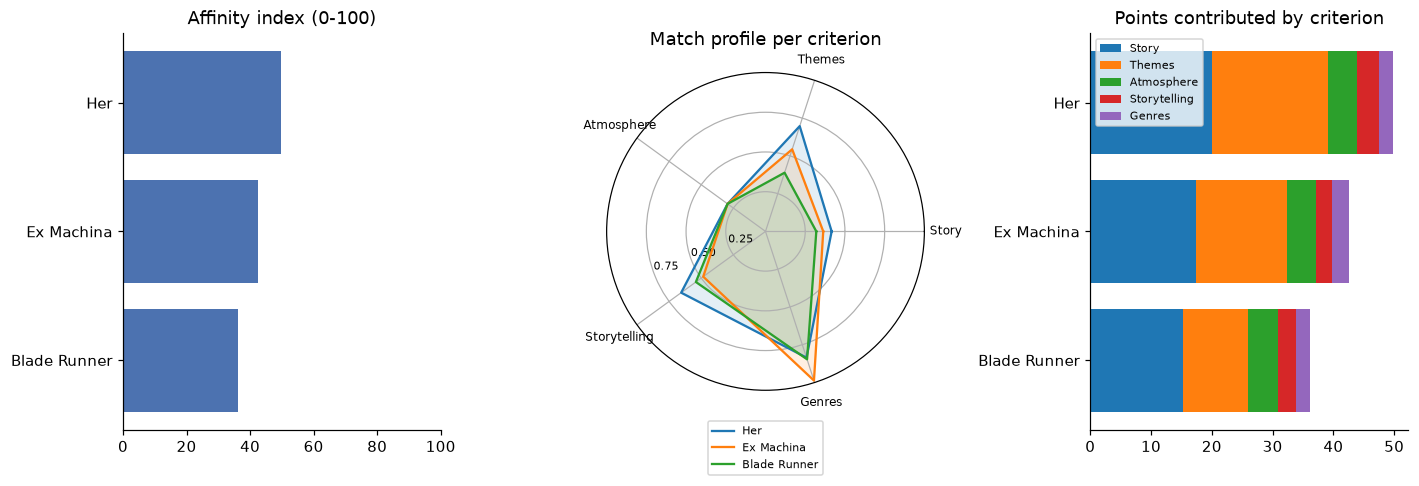

In [12]:
top = response.recommendations
criteria = [LABELS[k] for k in active]
titles = [r.movie.title for r in top]
sim = np.array([[next((c.similarity for c in r.criteria if c.label == label), 0.0) for label in criteria] for r in top])

fig = plt.figure(figsize=(13, 4.6))

# (a) Global affinity of the Top 3.
ax1 = fig.add_subplot(1, 3, 1)
ax1.barh(titles[::-1], [r.affinity for r in top][::-1], color="#4c72b0")
ax1.set_xlim(0, 100)
ax1.set_title("Affinity index (0-100)")

# (b) Radar chart: similarity per criterion, i.e. the coverage profile of each film.
ax2 = fig.add_subplot(1, 3, 2, polar=True)
angles = np.linspace(0, 2 * np.pi, len(criteria), endpoint=False).tolist()
for title, values in zip(titles, sim):
    ax2.plot(angles + angles[:1], list(values) + [values[0]], label=title)
    ax2.fill(angles + angles[:1], list(values) + [values[0]], alpha=0.12)
ax2.set_xticks(angles, criteria, fontsize=8)
ax2.set_ylim(0, 1)
ax2.set_rgrids([0.25, 0.5, 0.75], fontsize=7, angle=200)
ax2.set_title("Match profile per criterion", pad=18)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=7, ncol=1)

# (c) Stacked contributions: how many points each criterion brings.
ax3 = fig.add_subplot(1, 3, 3)
left = np.zeros(len(top))
for label in criteria:
    points = np.array([next((c.contribution for c in r.criteria if c.label == label), 0.0) for r in top])
    ax3.barh(titles[::-1], points[::-1], left=left[::-1], label=label)
    left += points
ax3.set_title("Points contributed by criterion")
ax3.legend(fontsize=7)
plt.tight_layout()
plt.show()

### Category-level coverage

Following the "competency coverage" idea of the assignment, we can also aggregate per *genre block*: for each genre, the mean affinity of its five best films. It shows which areas of the catalogue the user's text covers best.

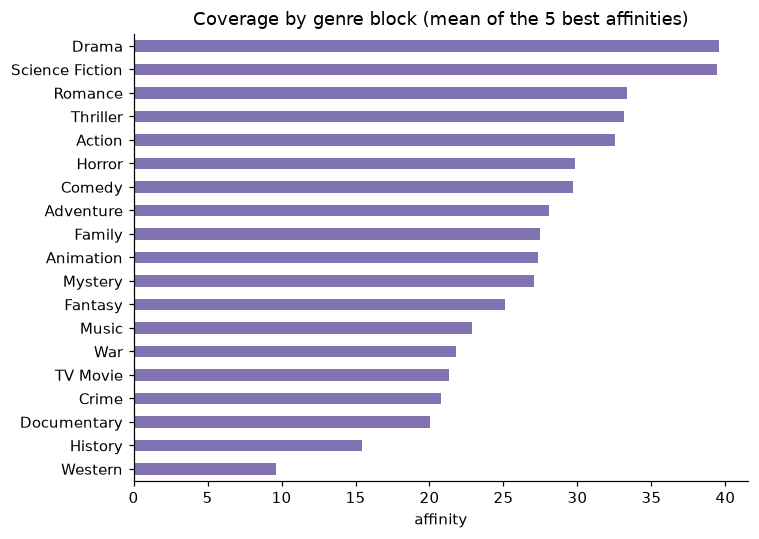

In [13]:
all_scores = recommender.recommend(profile, top_k=150).recommendations
by_genre = {}
for rec in all_scores:
    for genre in rec.movie.genres:
        by_genre.setdefault(genre, []).append(rec.affinity)
coverage = pd.Series({g: np.mean(sorted(v, reverse=True)[:5]) for g, v in by_genre.items() if len(v) >= 3}).sort_values()
coverage.plot.barh(figsize=(7, 5), color="#8172b2", title="Coverage by genre block (mean of the 5 best affinities)")
plt.xlabel("affinity")
plt.tight_layout()
plt.show()

### Similarity map

The 150 film profiles (the texts compared with the free description) projected from 384 dimensions to 2 with PCA, coloured by main genre. The star is the user request, the circled points the Top 3. Neighbouring points describe similar films even when they use different words. PCA keeps only a small part of the variance, so the map is an illustration; the ranking uses the full 384-dimensional cosine.

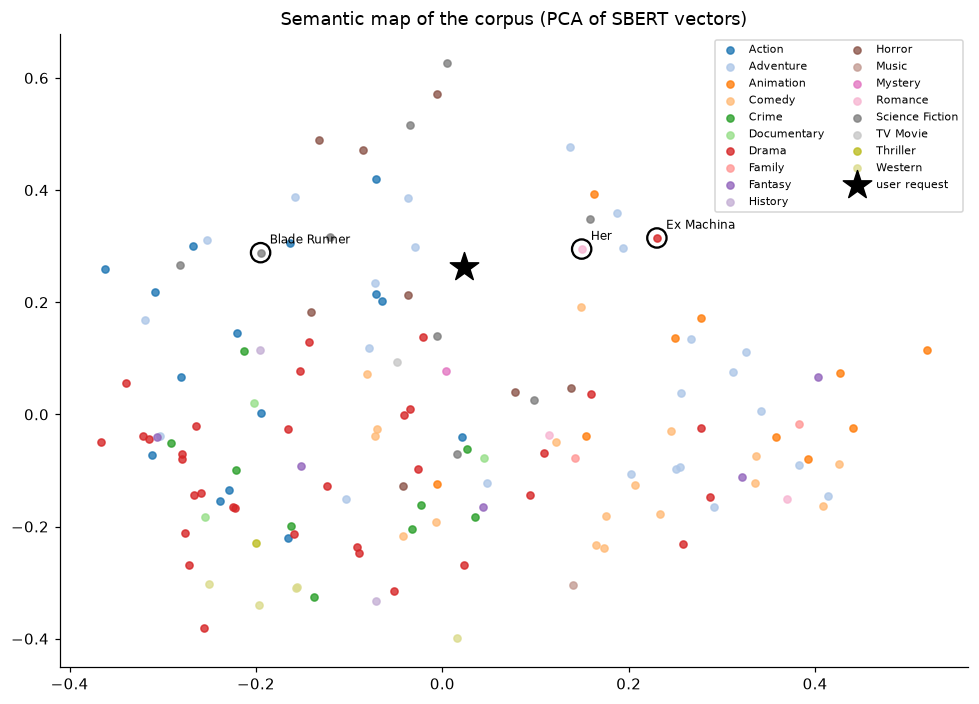

In [14]:
from sklearn.decomposition import PCA

film_vecs = recommender.semantic_fields[:, list(WEIGHTS).index("description"), :]
query_vec = encoder.encode([profile.description])
pca = PCA(n_components=2, random_state=0).fit(film_vecs)
points, query_point = pca.transform(film_vecs), pca.transform(query_vec)[0]

main_genre = [m.genres[0] for m in movies]
palette = {g: plt.cm.tab20(i % 20) for i, g in enumerate(sorted(set(main_genre)))}
fig, ax = plt.subplots(figsize=(9, 6.5))
for g in sorted(set(main_genre)):
    idx = [i for i, x in enumerate(main_genre) if x == g]
    ax.scatter(points[idx, 0], points[idx, 1], s=22, color=palette[g], label=g, alpha=0.8)
ax.scatter(*query_point, marker="*", s=380, color="black", label="user request")
for rec in top:
    i = next(i for i, m in enumerate(movies) if m.tmdb_id == rec.movie.tmdb_id)
    ax.scatter(*points[i], s=160, facecolors="none", edgecolors="black", linewidths=1.5)
    ax.annotate(rec.movie.title, points[i], xytext=(6, 6), textcoords="offset points", fontsize=8)
ax.legend(fontsize=7, ncol=2, loc="best")
ax.set_title("Semantic map of the corpus (PCA of SBERT vectors)")
plt.tight_layout()
plt.show()

## 9. Same request, three methods

The application lets the user switch the comparison method. With identical filters:

* **TF-IDF**: keyword overlap between the concatenated answers and the concatenated film text (baseline);
* **SBERT global**: one embedding for all answers vs one embedding per film;
* **SBERT by criterion** (default): the weighted formula of section 6.

In [15]:
rows = []
for method in ["tfidf", "sbert_global", "sbert_criteria"]:
    result = recommender.recommend(profile.model_copy(update={"method": method}), top_k=3)
    for rank, rec in enumerate(result.recommendations, 1):
        rows.append({"method": method, "rank": rank, "film": f"{rec.movie.title} ({rec.movie.release_year})", "affinity": round(rec.affinity, 1)})
pd.DataFrame(rows).pivot(index="rank", columns="method", values="film")

method,sbert_criteria,sbert_global,tfidf
rank,,,
1,Her (2013),Her (2013),Her (2013)
2,Ex Machina (2015),Ex Machina (2015),Ex Machina (2015)
3,Blade Runner (1982),World War Z (2013),The Terminator (1984)


### Paraphrase robustness

A request written without any word of the target synopsis. Keyword matching struggles; the semantic methods still find films about the described situation.

In [16]:
paraphrase = Preferences(description="A group of people stuck far from home in space must use science to survive and get back to Earth.")
for method in ["tfidf", "sbert_criteria"]:
    result = recommender.recommend(paraphrase.model_copy(update={"method": method}), top_k=3)
    print(f"{method:<15}", " | ".join(f"{r.movie.title} ({r.affinity:.0f})" for r in result.recommendations))

tfidf           Interstellar (10) | Alien³ (10) | The Lord of the Rings: The Fellowship of the Ring (8)
sbert_criteria  WALL·E (44) | Interstellar (41) | Aliens (40)


### Strict filters

Constraints are applied before ranking and never relaxed. Here the same request limited to films released between 1980 and 1999 and to 120 minutes. The ranking changes and the affinities drop, because the best semantic matches are excluded rather than the constraint being bent.

In [17]:
strict = profile.model_copy(update={"release_period": "1980-1999", "max_runtime": 120})
result = recommender.recommend(strict, top_k=3)
print(f"Eligible films: {result.eligible_count}")
for rec in result.recommendations:
    print(f"  {rec.movie.title} ({rec.movie.release_year}, {rec.movie.runtime_minutes} min) affinity {rec.affinity:.1f}")
for warning in result.warnings:
    print("Warning:", warning)

Eligible films: 20
  Blade Runner (1982, 117 min) affinity 36.1
  The Terminator (1984, 108 min) affinity 35.3
  Alien³ (1992, 114 min) affinity 27.0


## 10. Measured ranking quality

**Protocol.** 30 English requests (10 validation, 20 held-out test) covering paraphrases, mixed expectations and strict constraints. For each request the Top 10 of the three methods are pooled, and each candidate is judged from 0 to 3 (≥ 2 = relevant). Without a human panel, the judgments were produced by a local LLM (qwen3:14b via Ollama, temperature 0) that only sees source metadata, never our estimated labels. These are **automatic "silver" judgments**, reported as such. Metrics: Precision@3 and nDCG@3.

The scoring configuration was chosen on the validation split only, then the test split was used once.

In [18]:
selection = json.loads((ROOT / "evaluation/scoring-selection.json").read_text())
table = pd.DataFrame(selection["configurations"])
table["story compared with"] = table["story_scope"].map({"overview": "synopsis only", "profile": "whole film profile"})
table["extra overall criterion"] = (table["overall_weight"] * 100).astype(int).astype(str) + " %"
print("Validation split (selection of the scoring configuration):")
table[["story compared with", "extra overall criterion", "precision_at_3", "ndcg_at_3"]].round(3)

Validation split (selection of the scoring configuration):


,story compared with,extra overall criterion,precision_at_3,ndcg_at_3
0,synopsis only,0 %,0.500,0.498
1,synopsis only,25 %,0.567,0.521
2,synopsis only,50 %,0.567,0.527
3,whole film profile,0 %,0.567,0.574
4,whole film profile,25 %,0.533,0.558
5,whole film profile,50 %,0.533,0.544


,precision_at_3,ndcg_at_3,constraint_compliance,latency_ms
TF-IDF (keywords),0.367,0.366,1.0,42.400
SBERT global,0.450,0.485,1.0,45.998
SBERT by criterion,0.550,0.527,1.0,47.262


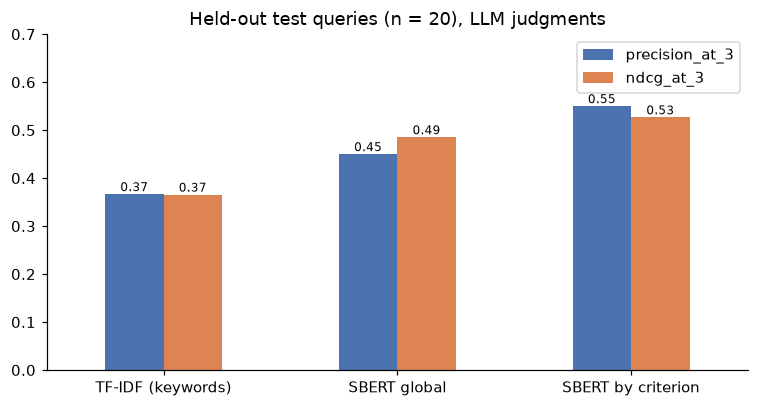

In [19]:
test = json.loads((ROOT / "evaluation/results-llm-test.json").read_text())
names = {"tfidf": "TF-IDF (keywords)", "sbert_global": "SBERT global", "sbert_criteria": "SBERT by criterion"}
results = pd.DataFrame(test["methods"]).T.rename(index=names)
display(results[["precision_at_3", "ndcg_at_3", "constraint_compliance", "latency_ms"]].round(3))

ax = results[["precision_at_3", "ndcg_at_3"]].plot.bar(figsize=(7, 3.8), rot=0, color=["#4c72b0", "#dd8452"])
ax.set_ylim(0, 0.7)
ax.set_title(f"Held-out test queries (n = {test['query_count']}), LLM judgments")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.show()

**Reading.** Semantic methods clearly beat the keyword baseline (P@3 0.45 and 0.55 vs 0.37), and organising the request by criterion adds about 10 points over a single global embedding, at the same latency (under 50 ms). With 20 queries one relevant film more or less moves P@3 by 1.7 points, so the gaps are indicative, not statistically established. Every method respected every strict constraint.

## 11. Limits and conclusion

* **Judgments**: automatic LLM judgments can share biases with the encoder; a human study with two annotators using the same pooling protocol is the next step.
* **Estimated labels**: atmosphere and storytelling are assigned by similarity, without human review; some are generic.
* **Negation**: sentence encoders do not understand "no horror" inside a positive field, which is why exclusions are separate filters and the API rejects negative wishes in text fields.
* **Language and size**: English only (language detection rejects other languages when confident); 150 films released up to 2016.
* **Affinity is not a probability** of enjoyment: it measures textual alignment.

The project meets each requirement with a transparent chain: free text → SBERT vectors → per-criterion cosine → weighted, renormalised affinity → Top 3 with evidence and charts. The same functions power the web application (`uvicorn backend.main:app`), which adds the interactive questionnaire, posters, the collection browser and the optional LLM critic.